# EDA — Dự báo Doanh thu Bán lẻ Đa kênh (Online / Store / Mobile)

**Dataset:** `retailhive_10k.csv` (giao dịch bán lẻ 2019–2025)

**Pipeline của notebook:**
1. Load dữ liệu giao dịch + gộp doanh thu theo tuần (tổng & theo từng kênh)
2. Thống kê mô tả (mean, std, min/max, quartile, hệ số biến thiên)
3. Biểu đồ xu hướng dài hạn (rolling trend) — tổng & theo kênh
4. Phân tích chu kỳ mùa vụ (STL decomposition, boxplot theo tháng, heatmap năm-tháng)
5. So sánh phân phối doanh thu tuần giữa 3 kênh (boxplot / violin / KDE)
6. Phát hiện & liệt kê outliers (phương pháp IQR) trên chuỗi doanh thu tuần
7. Xuất dữ liệu tuần đã gộp cho bước SARIMA / XGBoost tiếp theo

In [1]:
# Cài đặt statsmodels nếu môi trường (vd: Colab) chưa có sẵn
try:
    import statsmodels  # noqa: F401
except ImportError:
    %pip install -q statsmodels

import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL

## 0. Tải file dữ liệu lên (chỉ cần khi chạy trên Google Colab)

Notebook Colab chạy trên một máy ảo riêng, **không thấy được file trên máy tính của bạn** — vì vậy cần
tải `retailhive_10k.csv` lên trước. Chạy cell dưới đây:
- Nếu đang chạy trên **Colab**: một nút "Choose Files" sẽ hiện ra, chọn đúng file `retailhive_10k.csv`
  từ máy tính để tải lên (file sẽ nằm trong thư mục `/content/` của phiên Colab).
- Nếu đang chạy **local** (Jupyter/VS Code) và file đã có sẵn cùng thư mục với notebook: cell này sẽ tự
  bỏ qua bước upload và dùng thẳng file local, không cần làm gì thêm.

In [ ]:
import sys

if "google.colab" in sys.modules:
    from google.colab import files
    print("Đang chạy trên Google Colab — vui lòng chọn file retailhive_10k.csv để tải lên:")
    uploaded = files.upload()
    INPUT_FILE = list(uploaded.keys())[0]
    print(f"Đã tải lên: {INPUT_FILE}")
else:
    INPUT_FILE = "retailhive_10k.csv"

## 0.1. Cấu hình chung

In [ ]:
OUTPUT_DIR = "eda_outputs"

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"Online": "#4C72B0", "Store": "#DD8452", "Mobile": "#55A868"}

os.makedirs(OUTPUT_DIR, exist_ok=True)

## 1. Load dữ liệu + gộp doanh thu theo tuần

Dữ liệu gốc là dữ liệu **giao dịch chi tiết** (mỗi dòng = 1 giao dịch), chưa được tổng hợp theo tuần.
Bước đầu tiên là gộp doanh thu theo tuần lịch (tuần bắt đầu Chủ nhật, `W-SUN`), theo hai chiều:
- Gộp theo (tuần, kênh) → chuỗi doanh thu tuần riêng cho từng kênh
- Gộp theo tuần (không phân biệt kênh) → chuỗi tổng doanh thu toàn hệ thống

In [ ]:
df = pd.read_csv(INPUT_FILE, parse_dates=["date"])

# Chuẩn hóa mốc tuần theo tuần lịch (Chủ nhật -> Thứ Bảy)
df["week"] = df["date"].dt.to_period("W-SUN").dt.start_time

# 1a. Doanh thu tuần theo TỪNG KÊNH (long format - tiện cho seaborn)
weekly_channel = (
    df.groupby(["week", "channel"], as_index=False)["revenue"]
    .sum()
    .rename(columns={"revenue": "weekly_revenue"})
)

# 1b. Doanh thu tuần TỔNG hệ thống
weekly_total = (
    df.groupby("week", as_index=False)["revenue"]
    .sum()
    .rename(columns={"revenue": "weekly_revenue"})
)
weekly_total["channel"] = "Total"

# 1c. Pivot wide - mỗi cột là 1 kênh, tiện cho decomposition / rolling
weekly_wide = weekly_channel.pivot(index="week", columns="channel", values="weekly_revenue").fillna(0)
weekly_wide["Total"] = weekly_wide.sum(axis=1)
weekly_wide = weekly_wide.sort_index()

print("Số tuần quan sát:", weekly_wide.shape[0])
print("Khoảng thời gian:", weekly_wide.index.min().date(), "->", weekly_wide.index.max().date())
weekly_wide.head()

Số tuần quan sát: 366
Khoảng thời gian: 2018-12-31 -> 2025-12-29


channel,Mobile,Online,Store,Total
week,,,,
2018-12-31,1221.291525,949.926006,1204.944034,3376.161565
2019-01-07,1858.332382,904.494072,967.873135,3730.699588
2019-01-14,2405.362032,806.181663,1417.118730,4628.662425
2019-01-21,524.184306,736.292793,639.841805,1900.318903
2019-01-28,1270.779039,1306.866815,1097.428492,3675.074345


## 2. Thống kê mô tả (mean, std, min/max, quartiles)

In [ ]:
desc_stats = weekly_wide.describe().T
desc_stats["cv"] = desc_stats["std"] / desc_stats["mean"]  # hệ số biến thiên - so sánh biến động tương đối giữa kênh

print("=== THỐNG KÊ MÔ TẢ DOANH THU TUẦN (theo kênh & tổng) ===")
display_stats = desc_stats[["mean", "std", "min", "25%", "50%", "75%", "max", "cv"]].round(2)
display_stats.to_csv(f"{OUTPUT_DIR}/weekly_revenue_descriptive_stats.csv")
display_stats

=== THỐNG KÊ MÔ TẢ DOANH THU TUẦN (theo kênh & tổng) ===


,mean,std,min,25%,50%,75%,max,cv
channel,,,,,,,,
Mobile,1161.42,422.75,115.11,832.01,1121.91,1447.32,2419.62,0.36
Online,1085.71,401.53,274.91,803.91,1022.95,1324.08,2807.28,0.37
Store,1142.48,428.05,251.63,817.58,1109.69,1410.34,2750.14,0.37
Total,3389.61,743.39,1484.78,2904.89,3322.06,3875.37,5430.61,0.22


**Nhận xét:** Doanh thu trung bình tuần của ba kênh khá tương đồng nhau, hệ số biến thiên (CV) cũng xấp xỉ
nhau (~0.36–0.37) — không kênh nào biến động tương đối mạnh hơn hẳn kênh khác. CV của chuỗi **Tổng** thấp
hơn hẳn (0.22) do hiệu ứng gộp (aggregation) làm giảm biến động tương đối so với từng thành phần.

## 3. Biểu đồ xu hướng dài hạn (Trend Analysis)

Doanh thu tuần thực tế (đường nhạt) được vẽ cùng đường trung bình trượt 8 tuần (đường đậm) để làm mượt
nhiễu ngắn hạn và làm rõ xu hướng theo quý.

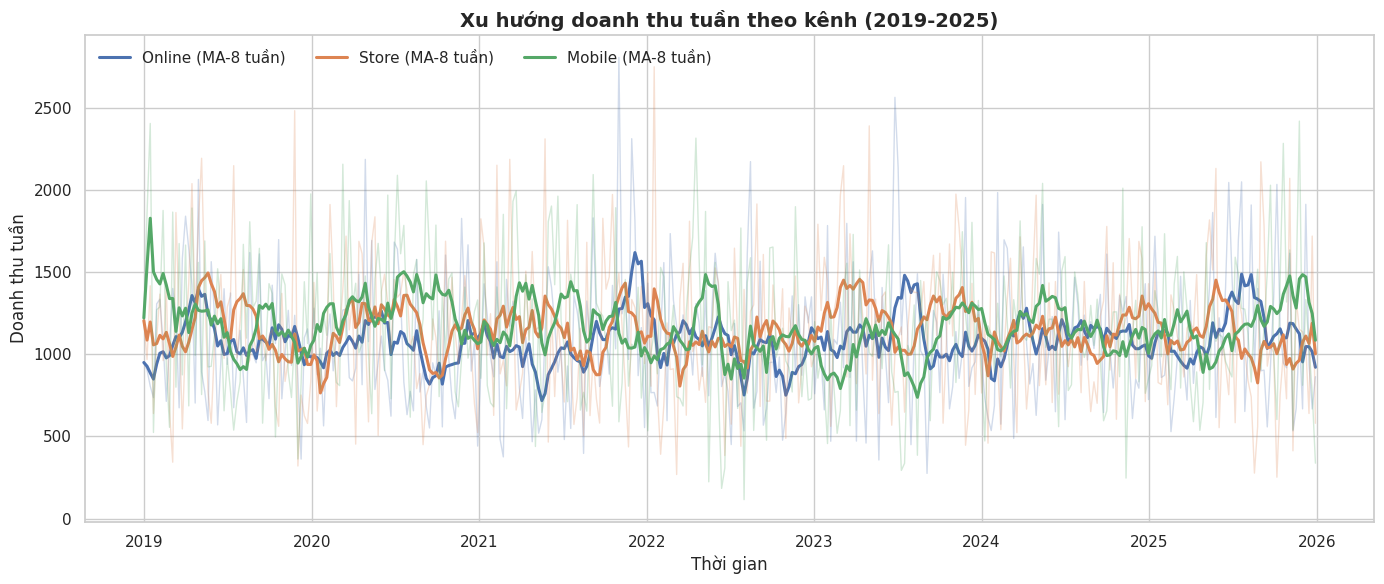

In [ ]:
fig, ax = plt.subplots(figsize=(14, 6))
for ch, color in PALETTE.items():
    ax.plot(weekly_wide.index, weekly_wide[ch], color=color, alpha=0.25, linewidth=1)
    ax.plot(
        weekly_wide.index,
        weekly_wide[ch].rolling(8, min_periods=1).mean(),
        color=color, linewidth=2.2, label=f"{ch} (MA-8 tuần)"
    )
ax.set_title("Xu hướng doanh thu tuần theo kênh (2019-2025)", fontsize=14, fontweight="bold")
ax.set_xlabel("Thời gian")
ax.set_ylabel("Doanh thu tuần")
ax.legend(ncol=3, loc="upper left", frameon=False)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/01_trend_by_channel.png", dpi=150)
plt.show()

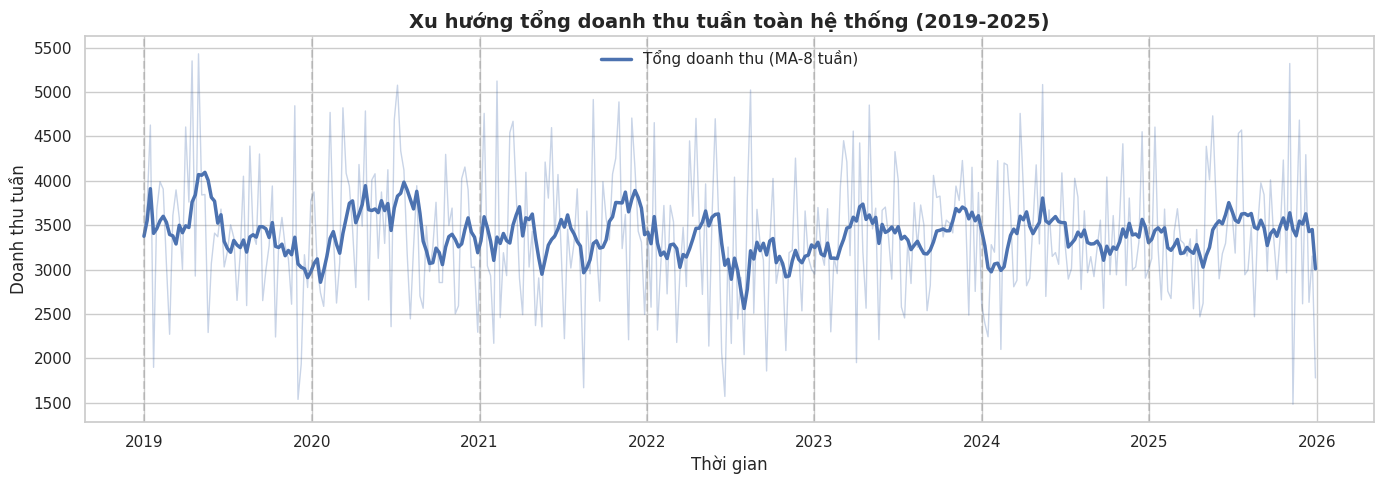

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(weekly_wide.index, weekly_wide["Total"], color="#4C72B0", alpha=0.3, linewidth=1)
ax.plot(weekly_wide.index, weekly_wide["Total"].rolling(8, min_periods=1).mean(),
        color="#4C72B0", linewidth=2.5, label="Tổng doanh thu (MA-8 tuần)")
for yr in range(2019, 2026):
    ax.axvline(pd.Timestamp(f"{yr}-01-01"), color="gray", linestyle="--", alpha=0.3)
ax.set_title("Xu hướng tổng doanh thu tuần toàn hệ thống (2019-2025)", fontsize=14, fontweight="bold")
ax.set_xlabel("Thời gian"); ax.set_ylabel("Doanh thu tuần")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/02_trend_total.png", dpi=150)
plt.show()

## 4. Phân tích chu kỳ mùa vụ (Seasonality)

### 4a. Phân rã chuỗi thời gian (STL decomposition)
Áp dụng STL (Seasonal-Trend decomposition using LOESS) với chu kỳ mùa vụ giả định 52 tuần/năm cho chuỗi
tổng doanh thu, tách thành Trend / Seasonal / Residual.

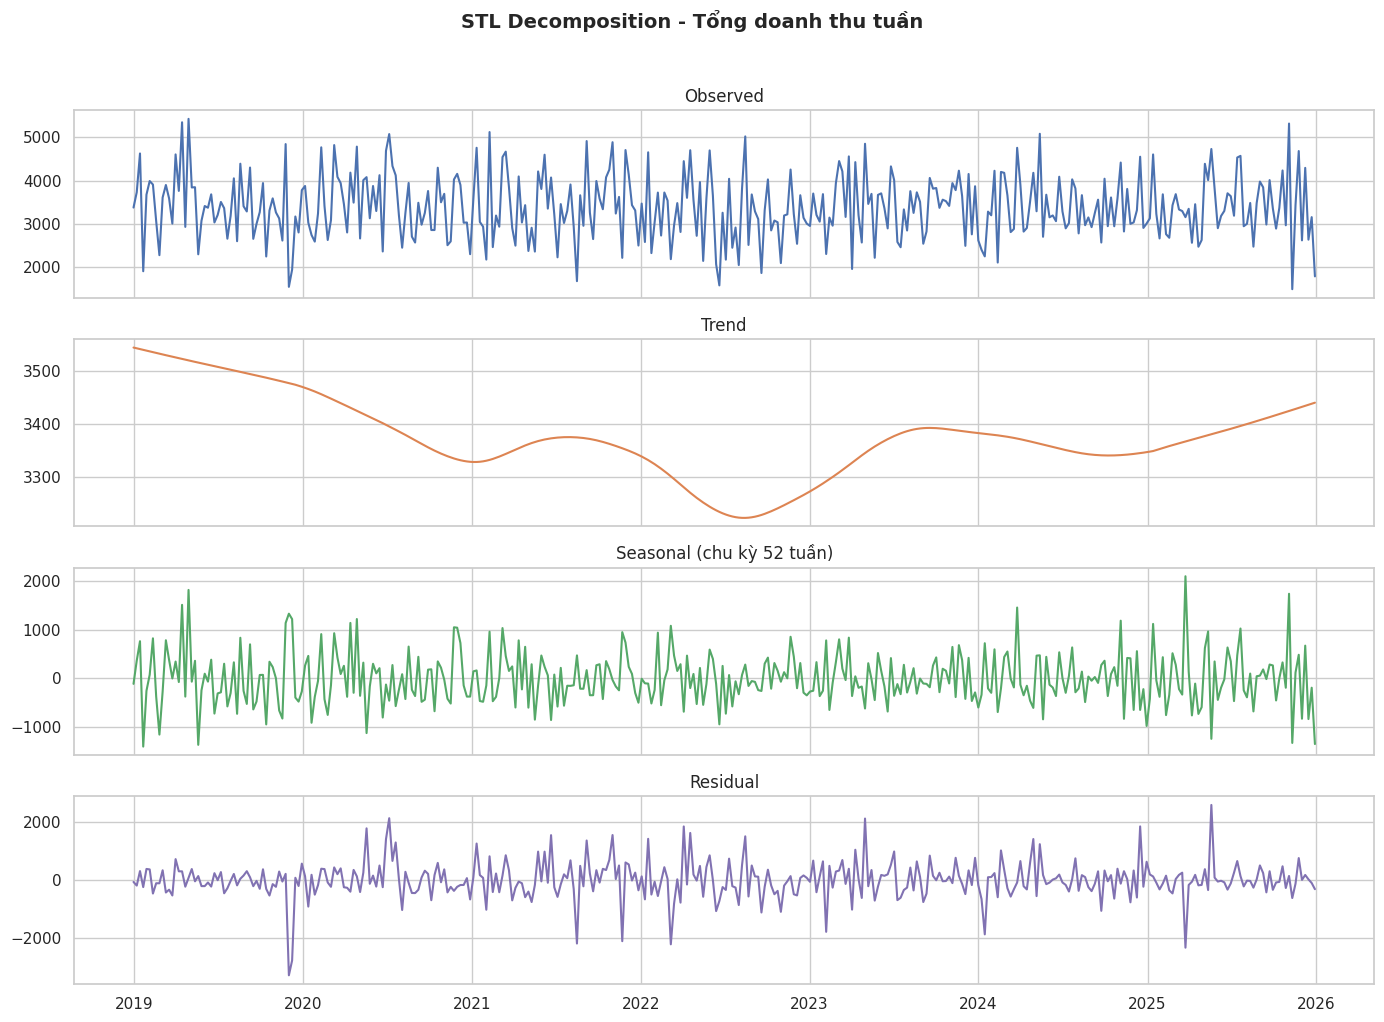

In [ ]:
ts_total = weekly_wide["Total"].asfreq("7D").interpolate()  # 7D vì mốc "week" là Thứ Hai đầu tuần, không phải Chủ nhật
stl = STL(ts_total, period=52, robust=True)
res = stl.fit()

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
axes[0].plot(ts_total.index, res.observed, color="#4C72B0"); axes[0].set_title("Observed")
axes[1].plot(ts_total.index, res.trend, color="#DD8452"); axes[1].set_title("Trend")
axes[2].plot(ts_total.index, res.seasonal, color="#55A868"); axes[2].set_title("Seasonal (chu kỳ 52 tuần)")
axes[3].plot(ts_total.index, res.resid, color="#8172B2"); axes[3].set_title("Residual")
fig.suptitle("STL Decomposition - Tổng doanh thu tuần", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/03_stl_decomposition_total.png", dpi=150, bbox_inches="tight")
plt.show()

### 4b. Phân phối doanh thu theo tháng trong năm (gộp tất cả các năm)

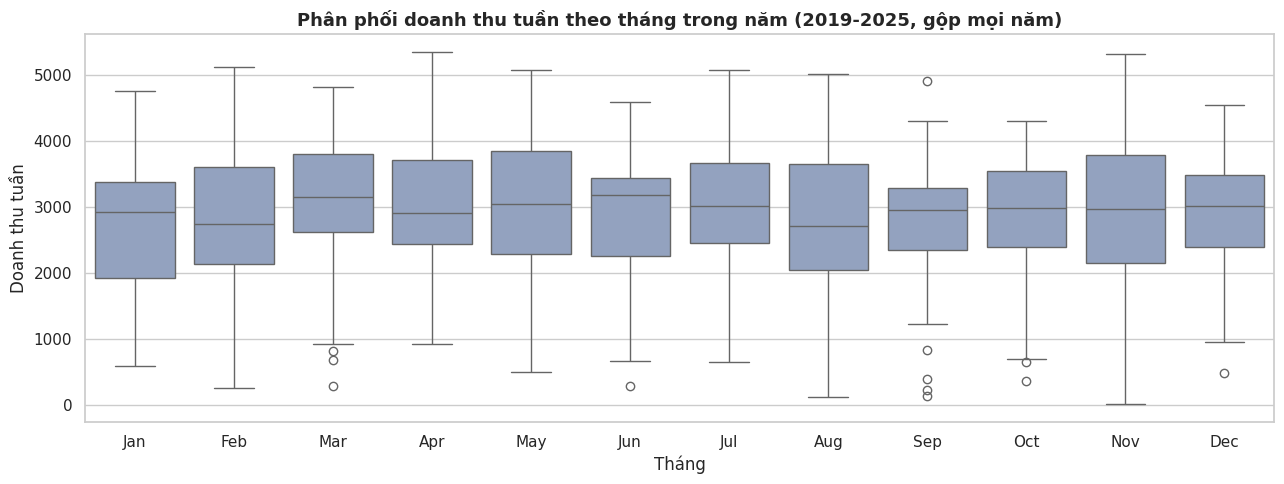

In [ ]:
df["month"] = df["date"].dt.month
month_revenue = df.groupby(["month", pd.Grouper(key="date", freq="W-SUN")])["revenue"].sum().reset_index()
month_revenue["month"] = month_revenue["date"].dt.month_name().str[:3]
month_order = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

fig, ax = plt.subplots(figsize=(13, 5))
sns.boxplot(data=month_revenue, x="month", y="revenue", order=month_order, ax=ax, color="#8CA0C6")
ax.set_title("Phân phối doanh thu tuần theo tháng trong năm (2019-2025, gộp mọi năm)", fontsize=13, fontweight="bold")
ax.set_xlabel("Tháng"); ax.set_ylabel("Doanh thu tuần")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/04_seasonality_by_month.png", dpi=150)
plt.show()

### 4c. Heatmap doanh thu theo Năm × Tháng
Kết hợp cả hai chiều thời gian giúp phân biệt biến động do mùa vụ (lặp lại theo tháng) và biến động do
xu hướng dài hạn (thay đổi qua các năm).

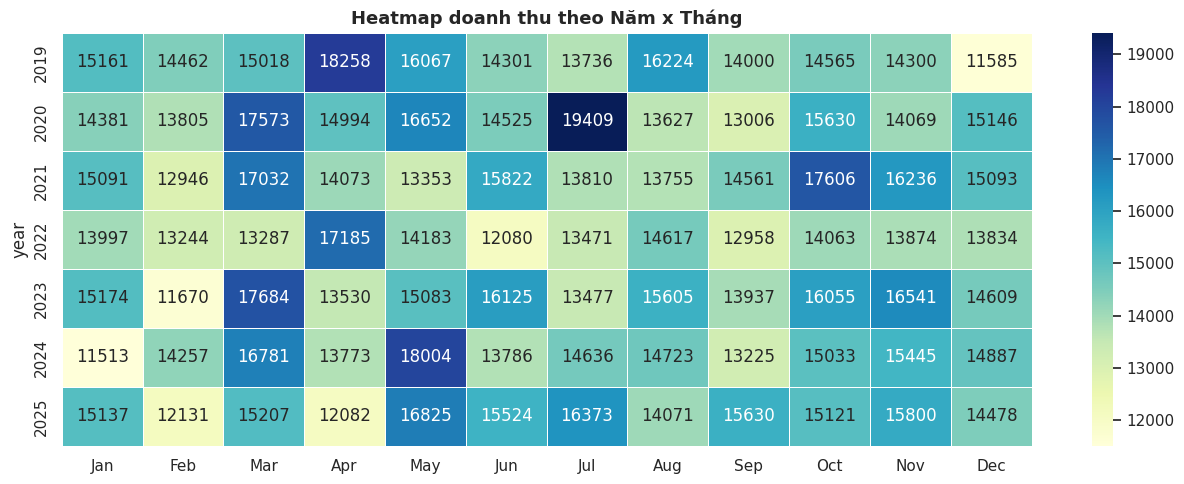

In [ ]:
pivot_year_month = (
    df.groupby([df["date"].dt.year.rename("year"), df["date"].dt.month.rename("month")])["revenue"]
    .sum()
    .unstack("month")
)
pivot_year_month.columns = [month_order[m-1] for m in pivot_year_month.columns]

fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(pivot_year_month, cmap="YlGnBu", annot=True, fmt=".0f", linewidths=0.5, ax=ax)
ax.set_title("Heatmap doanh thu theo Năm x Tháng", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/05_heatmap_year_month.png", dpi=150)
plt.show()

**Nhận xét mùa vụ:** Thành phần Seasonal (STL) có biên độ nhỏ so với Residual, và boxplot theo tháng
không cho thấy tháng nào nổi bật rõ rệt — gợi ý mùa vụ trong dữ liệu này tương đối yếu so với kỳ vọng
ban đầu của đề cương.

## 5. So sánh phân phối doanh thu giữa 3 kênh

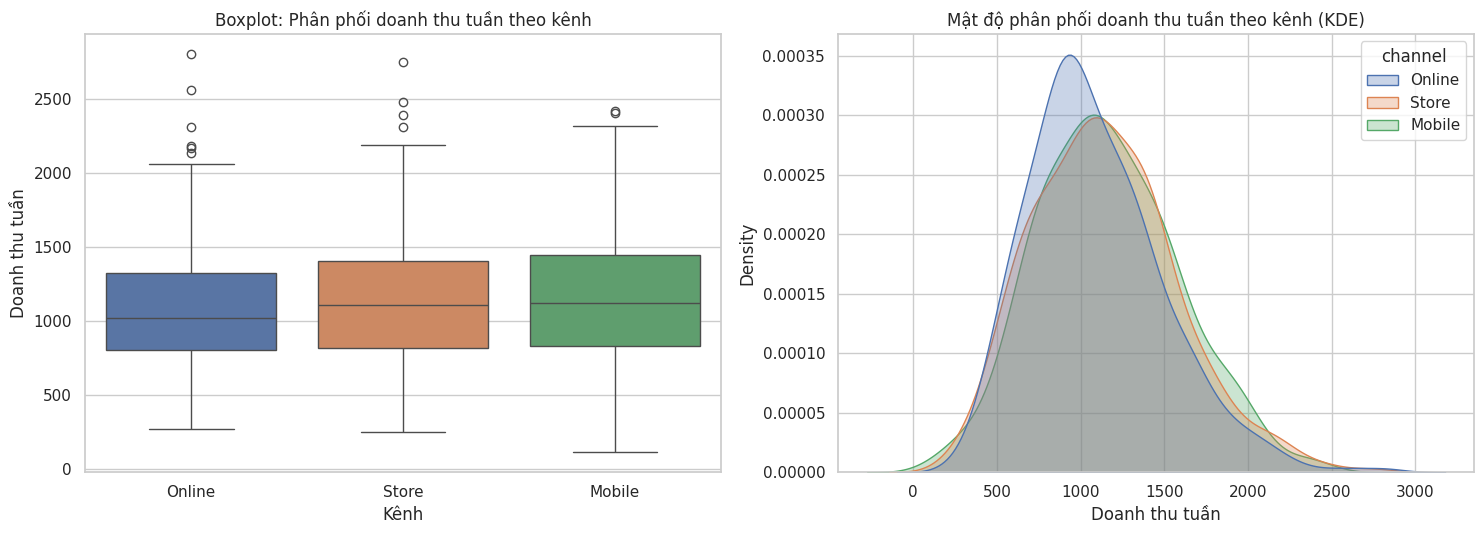

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.boxplot(data=weekly_channel, x="channel", y="weekly_revenue", hue="channel", legend=False,
            order=["Online", "Store", "Mobile"], palette=PALETTE, ax=axes[0])
axes[0].set_title("Boxplot: Phân phối doanh thu tuần theo kênh")
axes[0].set_xlabel("Kênh"); axes[0].set_ylabel("Doanh thu tuần")

sns.kdeplot(data=weekly_channel, x="weekly_revenue", hue="channel",
            hue_order=["Online", "Store", "Mobile"], palette=PALETTE,
            fill=True, alpha=0.3, ax=axes[1])
axes[1].set_title("Mật độ phân phối doanh thu tuần theo kênh (KDE)")
axes[1].set_xlabel("Doanh thu tuần")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/06_distribution_by_channel.png", dpi=150)
plt.show()

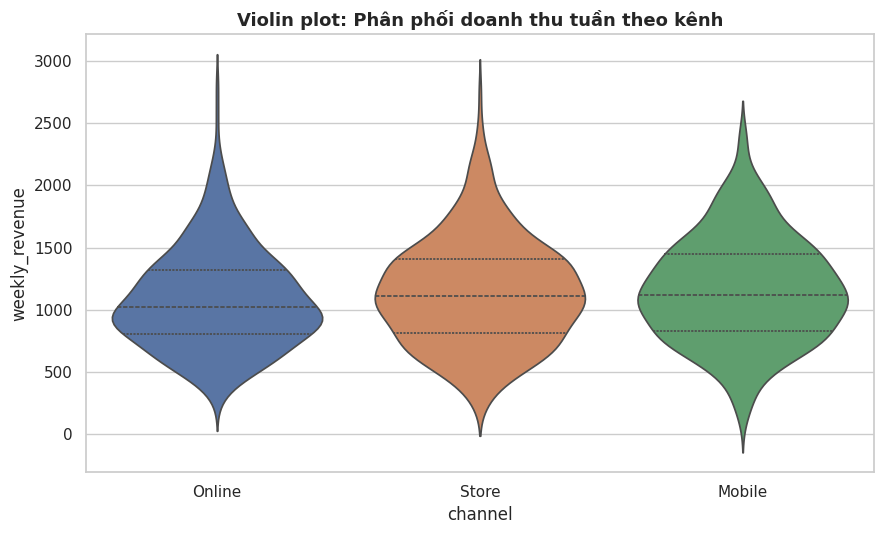

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.violinplot(data=weekly_channel, x="channel", y="weekly_revenue", hue="channel", legend=False,
                order=["Online", "Store", "Mobile"], palette=PALETTE, inner="quartile", ax=ax)
ax.set_title("Violin plot: Phân phối doanh thu tuần theo kênh", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/07_violin_by_channel.png", dpi=150)
plt.show()

**Nhận xét:** Phân phối doanh thu tuần của cả ba kênh có dạng lệch phải nhẹ, vị trí và độ rộng phân phối
khá gần nhau — không có sự phân hóa rõ rệt giữa Online / Store / Mobile ở cấp độ tổng thể.

## 6. Phát hiện Outliers (phương pháp IQR)

Một quan sát được xem là outlier nếu nằm ngoài khoảng `[Q1 - 1.5×IQR, Q3 + 1.5×IQR]`, áp dụng riêng cho
từng chuỗi (tổng hệ thống và từng kênh).

In [ ]:
def detect_outliers_iqr(series, k=1.5):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - k * iqr, q3 + k * iqr
    mask = (series < lower) | (series > upper)
    return mask, lower, upper

outlier_records = []
for ch in ["Total", "Online", "Store", "Mobile"]:
    mask, lower, upper = detect_outliers_iqr(weekly_wide[ch])
    n_out = mask.sum()
    print(f"[{ch}] Ngưỡng IQR: [{lower:.1f}, {upper:.1f}] -> {n_out} tuần outlier / {len(mask)} tuần "
          f"({n_out/len(mask)*100:.1f}%)")
    for wk in weekly_wide.index[mask]:
        outlier_records.append({
            "channel": ch, "week": wk.date(),
            "revenue": round(weekly_wide.loc[wk, ch], 1),
            "lower_bound": round(lower, 1), "upper_bound": round(upper, 1),
            "direction": "high" if weekly_wide.loc[wk, ch] > upper else "low"
        })

outliers_df = pd.DataFrame(outlier_records).sort_values(["channel", "week"])
outliers_df.to_csv(f"{OUTPUT_DIR}/outliers_iqr.csv", index=False)
print(f"\nĐã lưu chi tiết {len(outliers_df)} điểm outlier vào {OUTPUT_DIR}/outliers_iqr.csv")
outliers_df

[Total] Ngưỡng IQR: [1449.2, 5331.1] -> 2 tuần outlier / 366 tuần (0.5%)
[Online] Ngưỡng IQR: [23.6, 2104.3] -> 6 tuần outlier / 366 tuần (1.6%)
[Store] Ngưỡng IQR: [-71.6, 2299.5] -> 4 tuần outlier / 366 tuần (1.1%)
[Mobile] Ngưỡng IQR: [-90.9, 2370.3] -> 2 tuần outlier / 366 tuần (0.5%)

Đã lưu chi tiết 14 điểm outlier vào eda_outputs/outliers_iqr.csv


,channel,week,revenue,lower_bound,upper_bound,direction
12,Mobile,2019-01-14,2405.4,-90.9,2370.3,high
13,Mobile,2025-11-24,2419.6,-90.9,2370.3,high
2,Online,2020-04-27,2186.6,23.6,2104.3,high
3,Online,2021-11-01,2807.3,23.6,2104.3,high
4,Online,2021-11-29,2312.6,23.6,2104.3,high
5,Online,2022-08-15,2173.1,23.6,2104.3,high
6,Online,2023-06-26,2564.3,23.6,2104.3,high
7,Online,2023-07-03,2136.8,23.6,2104.3,high
8,Store,2019-11-25,2483.2,-71.6,2299.5,high
9,Store,2021-05-24,2311.4,-71.6,2299.5,high


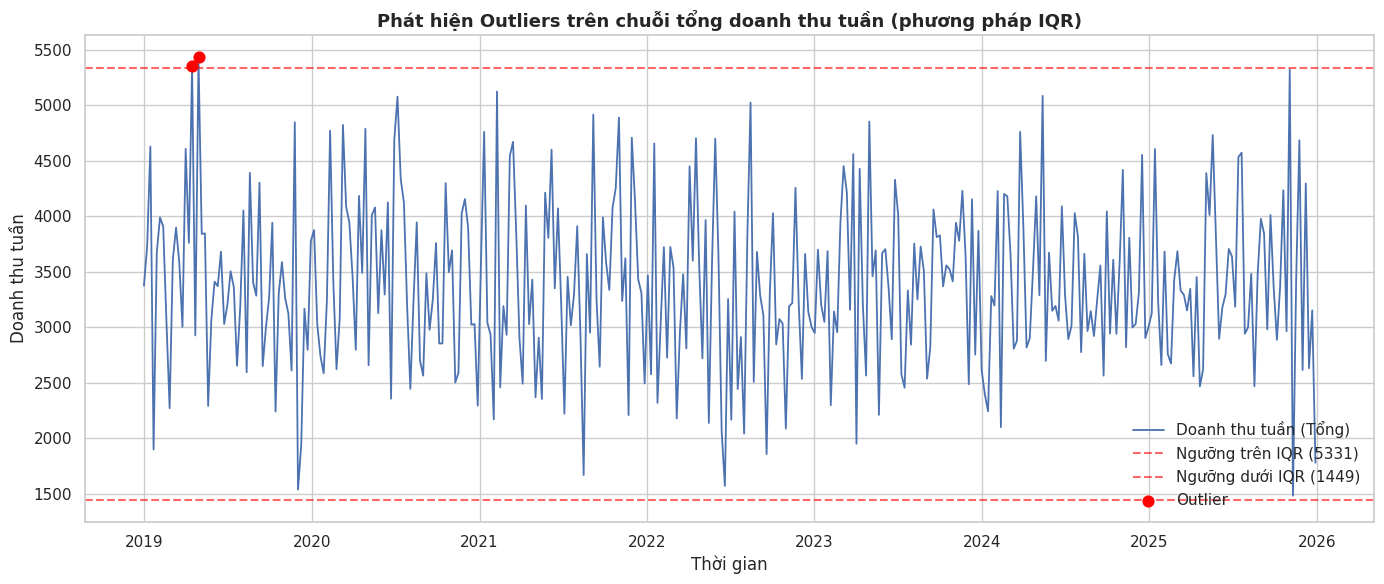

In [ ]:
mask_total, lower_total, upper_total = detect_outliers_iqr(weekly_wide["Total"])
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(weekly_wide.index, weekly_wide["Total"], color="#4C72B0", linewidth=1.3, label="Doanh thu tuần (Tổng)")
ax.axhline(upper_total, color="red", linestyle="--", alpha=0.6, label=f"Ngưỡng trên IQR ({upper_total:.0f})")
ax.axhline(lower_total, color="red", linestyle="--", alpha=0.6, label=f"Ngưỡng dưới IQR ({lower_total:.0f})")
ax.scatter(weekly_wide.index[mask_total], weekly_wide.loc[mask_total, "Total"],
           color="red", s=60, zorder=5, label="Outlier")
ax.set_title("Phát hiện Outliers trên chuỗi tổng doanh thu tuần (phương pháp IQR)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Thời gian"); ax.set_ylabel("Doanh thu tuần")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/08_outliers_total.png", dpi=150)
plt.show()

**Nhận xét:** Toàn bộ outlier phát hiện được đều lệch **cao** (không có outlier thấp bất thường), tỷ lệ
rất thấp (0.5%–1.6% số tuần) — dữ liệu tương đối "sạch". Các outlier nên được **gắn cờ làm đặc trưng**
(ví dụ `is_high_revenue_week`) cho XGBoost thay vì loại bỏ, vì nhiều khả năng phản ánh sự kiện kinh doanh
thật (khuyến mãi, cao điểm mùa vụ) chứ không phải lỗi dữ liệu.